# Eksperimen Paper: CNN Kustom Stable 6 Kelas Tanpa Tungro

Notebook ini dibuat untuk eksperimen paper dengan fokus pada **CNN Kustom** dan dataset **6 kelas tanpa Tungro**. Kelas Tungro dikeluarkan karena jumlah datanya jauh lebih besar dibanding kelas lain, sehingga eksperimen paper dibuat pada data yang lebih seimbang.

Target notebook:

1. Memuat dataset 6 kelas tanpa Tungro.
2. Melihat distribusi jumlah gambar per kelas.
3. Membagi data menjadi train, validation, dan test.
4. Membangun CNN Kustom Stable.
5. Melatih model 30 epoch.
6. Mengevaluasi model dengan accuracy, precision, recall, F1-score, dan confusion matrix.
7. Menyimpan output untuk bahan paper.

## 1. Setup Environment

Jalankan cell ini terlebih dahulu. Jika memakai VS Code, pilih kernel Python dari virtual environment project:

`rice_leaf_disease_project/.venv/Scripts/python.exe`

In [1]:
from pathlib import Path
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix

cwd = Path.cwd().resolve()
if cwd.name == "notebooks":
    PROJECT_ROOT = cwd.parent
elif cwd.name == "rice_leaf_disease_project":
    PROJECT_ROOT = cwd
else:
    PROJECT_ROOT = cwd / "rice_leaf_disease_project"

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from preprocessing.dataset_6_classes import (
    EXCLUDED_CLASS,
    SIX_CLASS_NAMES,
    collect_image_paths_and_labels,
    prepare_6_class_datasets,
)

OUTPUT_DIR = PROJECT_ROOT / "outputs"
REPORT_DIR = PROJECT_ROOT / "reports"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

Project root: C:\Users\farid\Downloads\archive (5)\rice_leaf_disease_project
TensorFlow: 2.10.1
GPU: []


## 2. Konfigurasi Eksperimen

Default notebook ini memakai `IMAGE_SIZE = 128` agar training lebih realistis dijalankan di CPU. Jika nanti hasilnya sudah stabil dan ingin kualitas citra lebih tinggi, nilai ini bisa dinaikkan ke `224` atau `256`, tetapi waktu training akan lebih lama.

In [2]:
EXPERIMENT_NAME = "custom_cnn_stable_6kelas_tanpa_tungro"

os.environ["RICE_EPOCHS"] = "30"
os.environ["RICE_IMAGE_SIZE"] = "128"
os.environ["RICE_BATCH_SIZE"] = "32"
os.environ["RICE_LEARNING_RATE"] = "0.0001"

EPOCHS = int(os.environ["RICE_EPOCHS"])
IMAGE_SIZE = int(os.environ["RICE_IMAGE_SIZE"])
BATCH_SIZE = int(os.environ["RICE_BATCH_SIZE"])
LEARNING_RATE = float(os.environ["RICE_LEARNING_RATE"])

MODEL_PATH = OUTPUT_DIR / f"{EXPERIMENT_NAME}.keras"
BEST_MODEL_PATH = OUTPUT_DIR / f"{EXPERIMENT_NAME}_best.keras"
CSV_LOG_PATH = REPORT_DIR / f"training_log_{EXPERIMENT_NAME}.csv"
SUMMARY_PATH = REPORT_DIR / f"ringkasan_{EXPERIMENT_NAME}.csv"
REPORT_PATH = REPORT_DIR / f"classification_report_{EXPERIMENT_NAME}.txt"
CONFUSION_MATRIX_PATH = REPORT_DIR / f"confusion_matrix_{EXPERIMENT_NAME}.png"
TRAINING_PLOT_PATH = REPORT_DIR / f"grafik_pelatihan_{EXPERIMENT_NAME}.png"

print("Experiment:", EXPERIMENT_NAME)
print("Epochs:", EPOCHS)
print("Image size:", IMAGE_SIZE)
print("Batch size:", BATCH_SIZE)
print("Learning rate:", LEARNING_RATE)

Experiment: custom_cnn_stable_6kelas_tanpa_tungro
Epochs: 30
Image size: 128
Batch size: 32
Learning rate: 0.0001


## 3. Distribusi Dataset 6 Kelas

Cell ini memastikan bahwa kelas Tungro tidak ikut digunakan. Distribusi data dicek agar alasan metodologis paper lebih kuat: enam kelas yang digunakan relatif seimbang.

In [3]:
image_paths, labels, class_names = collect_image_paths_and_labels()

class_distribution = pd.DataFrame(
    {
        "class_name": class_names,
        "image_count": [labels.count(i) for i in range(len(class_names))],
    }
)

display(class_distribution)
print("Total gambar:", len(image_paths))
print("Kelas yang dikeluarkan:", EXCLUDED_CLASS)

,class_name,image_count
0,Bacterial Leaf Blight,636
1,Brown Spot,646
2,Healthy Rice Leaf,653
3,Leaf Blast,634
4,Leaf scald,628
5,Sheath Blight,632


Total gambar: 3829
Kelas yang dikeluarkan: Tungro


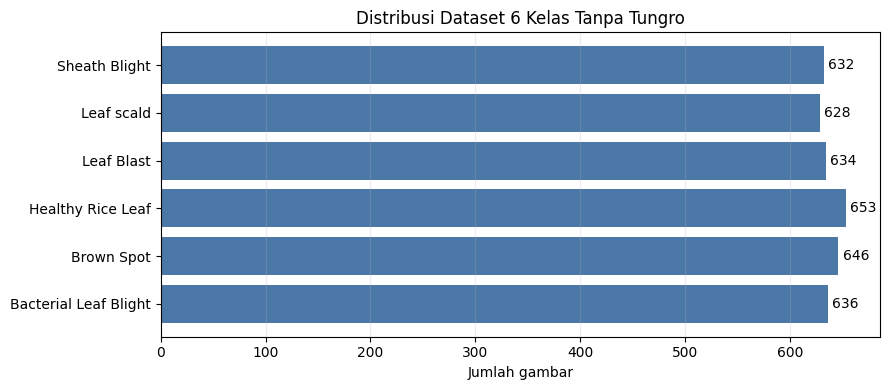

In [4]:
plt.figure(figsize=(9, 4))
bars = plt.barh(class_distribution["class_name"], class_distribution["image_count"], color="#4C78A8")
plt.xlabel("Jumlah gambar")
plt.title("Distribusi Dataset 6 Kelas Tanpa Tungro")
plt.grid(axis="x", alpha=0.25)
for bar in bars:
    width = bar.get_width()
    plt.text(width + 4, bar.get_y() + bar.get_height() / 2, int(width), va="center")
plt.tight_layout()
plt.show()

## 4. Load Dataset dan Split Data

Dataset dibagi menjadi train, validation, dan test secara stratified. Artinya, proporsi setiap kelas dijaga agar tetap relatif seimbang pada setiap subset.

In [5]:
from dataclasses import replace
from configuration.settings import SETTINGS

settings = replace(
    SETTINGS,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    class_names=SIX_CLASS_NAMES,
    model_name=EXPERIMENT_NAME,
)

train_ds, val_ds, test_ds, metadata = prepare_6_class_datasets(settings)

metadata_df = pd.DataFrame([metadata])
display(metadata_df)
print("Class names:", metadata["class_names"])

,class_names,num_classes,excluded_class,total_images,train_images,val_images,test_images,train_batches,val_batches,test_batches
0,"[Bacterial Leaf Blight, Brown Spot, Healthy Ri...",6,Tungro,3829,2680,574,575,84,18,18


Class names: ['Bacterial Leaf Blight', 'Brown Spot', 'Healthy Rice Leaf', 'Leaf Blast', 'Leaf scald', 'Sheath Blight']


## 5. Preview Sampel Gambar

Preview ini membantu memastikan gambar dan label terbaca dengan benar.

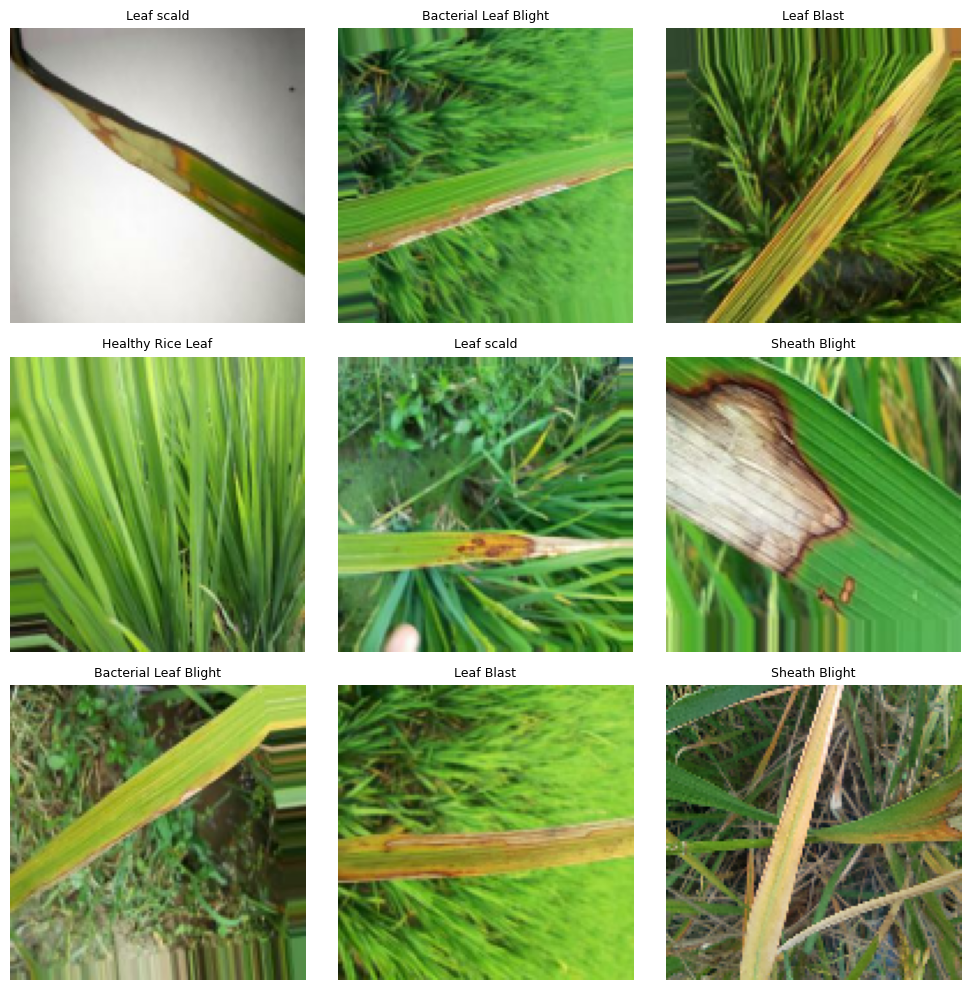

In [6]:
plt.figure(figsize=(10, 10))
for images, batch_labels in train_ds.take(1):
    for i in range(min(9, len(images))):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[int(batch_labels[i].numpy())], fontsize=9)
        plt.axis("off")
plt.tight_layout()
plt.show()

## 6. Model CNN Kustom Stable

Model ini tetap CNN Kustom, bukan transfer learning. Perubahan dari CNN awal:

- Jumlah blok konvolusi ditambah agar fitur visual lebih kaya.
- Dropout digunakan untuk mengurangi overfitting.
- Learning rate dibuat kecil agar training lebih stabil.
- ModelCheckpoint menyimpan model terbaik berdasarkan `val_accuracy`.

In [7]:
from tensorflow import keras
from tensorflow.keras import layers

def build_custom_cnn_stable(image_size: int, num_classes: int) -> keras.Model:
    data_augmentation = keras.Sequential(
        [
            layers.RandomFlip("horizontal_and_vertical"),
            layers.RandomRotation(0.10),
            layers.RandomZoom(0.10),
        ],
        name="stable_data_augmentation",
    )

    model = keras.Sequential(
        [
            layers.InputLayer(input_shape=(image_size, image_size, 3)),
            layers.Rescaling(1.0 / 255),
            data_augmentation,
            layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
            layers.MaxPooling2D(),
            layers.Dropout(0.10),
            layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
            layers.MaxPooling2D(),
            layers.Dropout(0.15),
            layers.Conv2D(128, (3, 3), padding="same", activation="relu"),
            layers.MaxPooling2D(),
            layers.Dropout(0.20),
            layers.Conv2D(128, (3, 3), padding="same", activation="relu"),
            layers.MaxPooling2D(),
            layers.Flatten(),
            layers.Dense(256, activation="relu"),
            layers.Dropout(0.50),
            layers.Dense(num_classes, name="output"),
        ],
        name=EXPERIMENT_NAME,
    )

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        metrics=["accuracy"],
    )
    return model

model = build_custom_cnn_stable(IMAGE_SIZE, len(class_names))
model.summary()

Model: "custom_cnn_stable_6kelas_tanpa_tungro"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 rescaling (Rescaling)       (None, 128, 128, 3)       0         
                                                                 
 stable_data_augmentation (S  (None, 128, 128, 3)      0         
 equential)                                                      
                                                                 
 conv2d (Conv2D)             (None, 128, 128, 32)      896       
                                                                 
 max_pooling2d (MaxPooling2D  (None, 64, 64, 32)       0         
 )                                                               
                                                                 
 dropout (Dropout)           (None, 64, 64, 32)        0         
                                                                 
 conv2d_1 (Conv2D)           

## 7. Training 30 Epoch

Cell ini menjalankan training. Jika memakai CPU, proses bisa cukup lama. Model terbaik akan otomatis disimpan ke file `custom_cnn_stable_6kelas_tanpa_tungro_best.keras`.

In [8]:
callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath=str(BEST_MODEL_PATH),
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1,
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=8,
        restore_best_weights=True,
        verbose=1,
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1,
    ),
    keras.callbacks.CSVLogger(str(CSV_LOG_PATH)),
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1,
)

model.save(MODEL_PATH)
print("Model akhir disimpan ke:", MODEL_PATH)
print("Model terbaik disimpan ke:", BEST_MODEL_PATH)

Epoch 1/30
84/84 [==============================] - ETA: 0s - loss: 1.7673 - accuracy: 0.2175
Epoch 1: val_accuracy improved from -inf to 0.29094, saving model to C:\Users\farid\Downloads\archive (5)\rice_leaf_disease_project\outputs\custom_cnn_stable_6kelas_tanpa_tungro_best.keras
84/84 [==============================] - 59s 637ms/step - loss: 1.7673 - accuracy: 0.2175 - val_loss: 1.7052 - val_accuracy: 0.2909 - lr: 1.0000e-04
Epoch 2/30
84/84 [==============================] - ETA: 0s - loss: 1.5991 - accuracy: 0.3511
Epoch 2: val_accuracy improved from 0.29094 to 0.36411, saving model to C:\Users\farid\Downloads\archive (5)\rice_leaf_disease_project\outputs\custom_cnn_stable_6kelas_tanpa_tungro_best.keras
84/84 [==============================] - 50s 599ms/step - loss: 1.5991 - accuracy: 0.3511 - val_loss: 1.5815 - val_accuracy: 0.3641 - lr: 1.0000e-04
Epoch 3/30
84/84 [==============================] - ETA: 0s - loss: 1.4279 - accuracy: 0.4291
Epoch 3: val_accuracy improved from 0.3

## 8. Grafik Training

Grafik ini digunakan untuk melihat apakah model overfitting atau masih belajar dengan baik.

,loss,accuracy,val_loss,val_accuracy,lr
22,0.652842,0.766418,1.025052,0.621951,0.000050
23,0.646564,0.774627,1.027912,0.627178,0.000050
24,0.638301,0.767164,1.030087,0.630662,0.000050
25,0.599979,0.785448,1.042978,0.620209,0.000025
26,0.599095,0.794403,1.019659,0.623693,0.000025


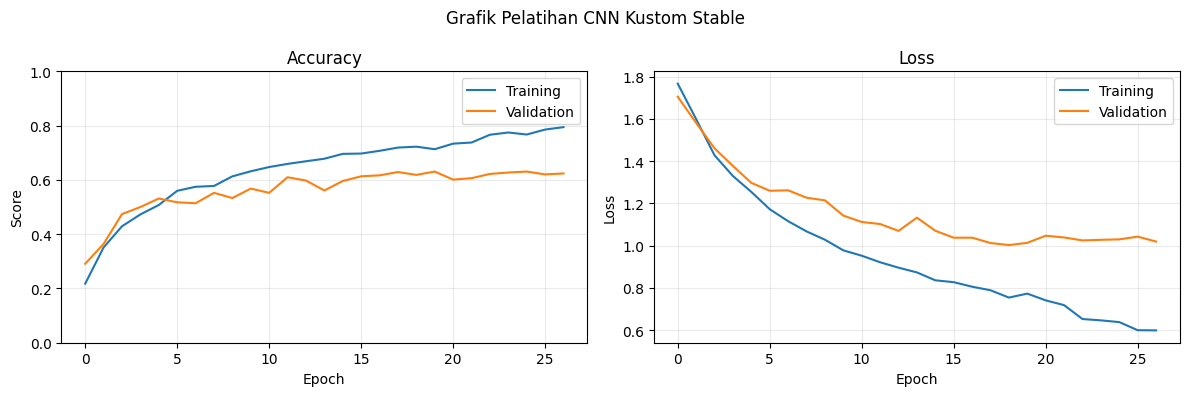

Grafik disimpan ke: C:\Users\farid\Downloads\archive (5)\rice_leaf_disease_project\reports\grafik_pelatihan_custom_cnn_stable_6kelas_tanpa_tungro.png


In [9]:
history_df = pd.DataFrame(history.history)
display(history_df.tail())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history_df["accuracy"], label="Training")
axes[0].plot(history_df["val_accuracy"], label="Validation")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Score")
axes[0].set_ylim(0, 1)
axes[0].grid(alpha=0.25)
axes[0].legend()

axes[1].plot(history_df["loss"], label="Training")
axes[1].plot(history_df["val_loss"], label="Validation")
axes[1].set_title("Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].grid(alpha=0.25)
axes[1].legend()

plt.suptitle("Grafik Pelatihan CNN Kustom Stable")
plt.tight_layout()
plt.savefig(TRAINING_PLOT_PATH, dpi=150, bbox_inches="tight")
plt.show()

print("Grafik disimpan ke:", TRAINING_PLOT_PATH)

## 9. Evaluasi Model Terbaik pada Test Set

Evaluasi dilakukan pada test set yang tidak digunakan dalam training. Jika file best checkpoint tersedia, notebook akan memakai model terbaik berdasarkan validation accuracy.

In [10]:
best_model = keras.models.load_model(BEST_MODEL_PATH) if BEST_MODEL_PATH.exists() else model

test_loss, test_accuracy = best_model.evaluate(test_ds, verbose=1)
print(f"Test loss    : {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")

18/18 [==============================] - 2s 113ms/step - loss: 1.0129 - accuracy: 0.6157
Test loss    : 1.0129
Test accuracy: 0.6157


In [11]:
y_true = []
y_pred = []

for images, batch_labels in test_ds:
    logits = best_model.predict(images, verbose=0)
    predictions = np.argmax(logits, axis=1)
    y_pred.extend(predictions.tolist())
    y_true.extend(batch_labels.numpy().tolist())

report_text = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    zero_division=0,
)

print(report_text)
REPORT_PATH.write_text(report_text, encoding="utf-8")
print("Classification report disimpan ke:", REPORT_PATH)

                       precision    recall  f1-score   support

Bacterial Leaf Blight       0.65      0.53      0.59        96
           Brown Spot       0.64      0.66      0.65        97
    Healthy Rice Leaf       0.91      0.88      0.89        98
           Leaf Blast       0.61      0.66      0.63        95
           Leaf scald       0.39      0.63      0.48        94
        Sheath Blight       0.67      0.33      0.44        95

             accuracy                           0.62       575
            macro avg       0.64      0.61      0.61       575
         weighted avg       0.65      0.62      0.62       575

Classification report disimpan ke: C:\Users\farid\Downloads\archive (5)\rice_leaf_disease_project\reports\classification_report_custom_cnn_stable_6kelas_tanpa_tungro.txt


## 10. Confusion Matrix

Confusion matrix menunjukkan kelas mana yang sering benar dan kelas mana yang sering tertukar.

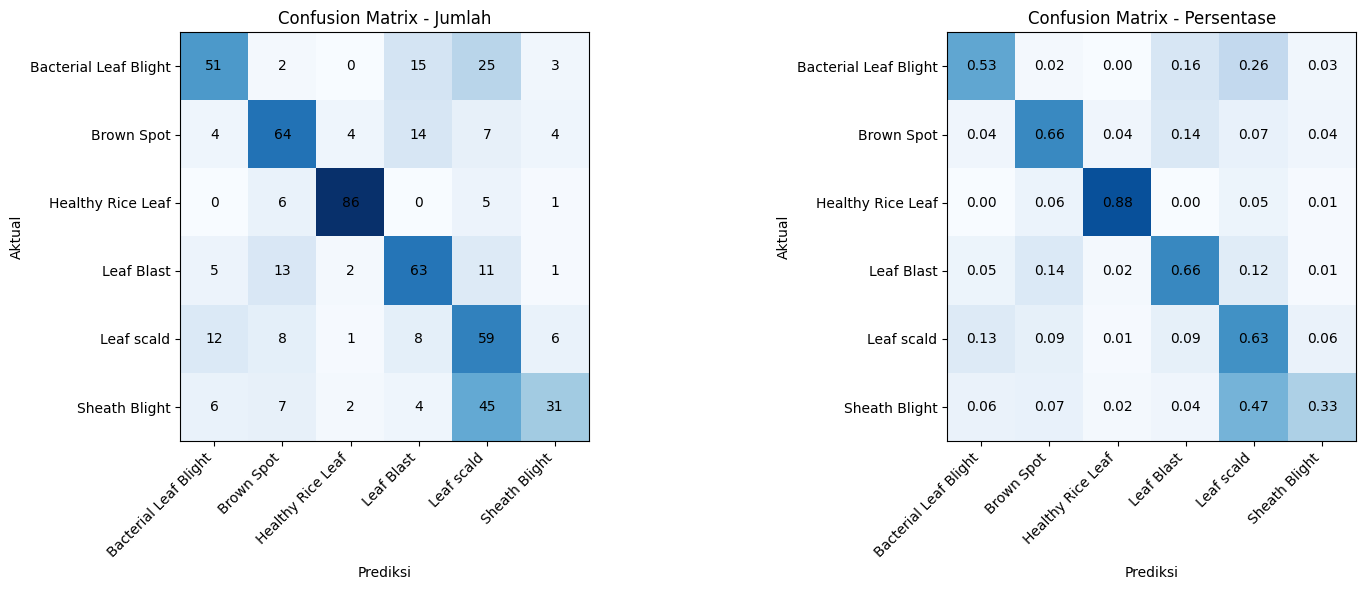

Confusion matrix disimpan ke: C:\Users\farid\Downloads\archive (5)\rice_leaf_disease_project\reports\confusion_matrix_custom_cnn_stable_6kelas_tanpa_tungro.png


In [12]:
cm = confusion_matrix(y_true, y_pred)
cm_norm = cm.astype("float") / cm.sum(axis=1, keepdims=True)
cm_norm = np.nan_to_num(cm_norm)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

im0 = axes[0].imshow(cm, cmap="Blues")
axes[0].set_title("Confusion Matrix - Jumlah")
axes[0].set_xticks(np.arange(len(class_names)))
axes[0].set_yticks(np.arange(len(class_names)))
axes[0].set_xticklabels(class_names, rotation=45, ha="right")
axes[0].set_yticklabels(class_names)
axes[0].set_xlabel("Prediksi")
axes[0].set_ylabel("Aktual")

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        axes[0].text(j, i, cm[i, j], ha="center", va="center", color="black")

im1 = axes[1].imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
axes[1].set_title("Confusion Matrix - Persentase")
axes[1].set_xticks(np.arange(len(class_names)))
axes[1].set_yticks(np.arange(len(class_names)))
axes[1].set_xticklabels(class_names, rotation=45, ha="right")
axes[1].set_yticklabels(class_names)
axes[1].set_xlabel("Prediksi")
axes[1].set_ylabel("Aktual")

for i in range(cm_norm.shape[0]):
    for j in range(cm_norm.shape[1]):
        axes[1].text(j, i, f"{cm_norm[i, j]:.2f}", ha="center", va="center", color="black")

plt.tight_layout()
plt.savefig(CONFUSION_MATRIX_PATH, dpi=150, bbox_inches="tight")
plt.show()

print("Confusion matrix disimpan ke:", CONFUSION_MATRIX_PATH)

## 11. Ringkasan Hasil untuk Paper

Cell ini menyimpan metrik utama ke CSV agar mudah dikutip ke paper.

In [13]:
report_dict = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    output_dict=True,
    zero_division=0,
)

summary = {
    "experiment": EXPERIMENT_NAME,
    "model": "CNN Kustom Stable",
    "num_classes": len(class_names),
    "excluded_class": EXCLUDED_CLASS,
    "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE,
    "epochs_configured": EPOCHS,
    "epochs_ran": len(history_df),
    "test_accuracy": report_dict["accuracy"],
    "precision_macro": report_dict["macro avg"]["precision"],
    "recall_macro": report_dict["macro avg"]["recall"],
    "f1_macro": report_dict["macro avg"]["f1-score"],
    "precision_weighted": report_dict["weighted avg"]["precision"],
    "recall_weighted": report_dict["weighted avg"]["recall"],
    "f1_weighted": report_dict["weighted avg"]["f1-score"],
}

summary_df = pd.DataFrame([summary])
summary_df.to_csv(SUMMARY_PATH, index=False)
display(summary_df)
print("Ringkasan disimpan ke:", SUMMARY_PATH)

,experiment,model,num_classes,excluded_class,image_size,batch_size,epochs_configured,epochs_ran,test_accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted
0,custom_cnn_stable_6kelas_tanpa_tungro,CNN Kustom Stable,6,Tungro,128,32,30,27,0.615652,0.644492,0.614288,0.613284,0.646299,0.615652,0.615046


Ringkasan disimpan ke: C:\Users\farid\Downloads\archive (5)\rice_leaf_disease_project\reports\ringkasan_custom_cnn_stable_6kelas_tanpa_tungro.csv


## 12. Catatan Interpretasi untuk Paper

Narasi yang bisa dipakai:

Penelitian ini menggunakan enam kelas citra daun padi dengan distribusi data yang relatif seimbang. Kelas Tungro tidak digunakan pada eksperimen paper karena jumlah citranya jauh lebih besar dibandingkan kelas lain, sehingga dapat memengaruhi evaluasi model. CNN Kustom Stable dibangun menggunakan beberapa blok konvolusi, pooling, dropout, dan dense layer. Evaluasi dilakukan menggunakan accuracy, precision, recall, F1-score, dan confusion matrix pada test set.

Jika hasil CNN Kustom Stable masih belum cukup tinggi, ada dua opsi akademik yang aman:

1. Tetap gunakan hasil tersebut sebagai baseline CNN Kustom dan jelaskan keterbatasannya.
2. Tambahkan eksperimen lanjutan dengan image size lebih besar atau transfer learning, tetapi pastikan arah paper tetap konsisten.